# **Model Performance and Comparison**

To evaluate and compare model performance, we utilize the following metrics derived from the **Confusion Matrix** (Error Matrix):

* **Confusion Matrix Components:**
  * **True Positive (TP):** Diabetic individuals correctly predicted as Diabetic.
  * **True Negative (TN):** Healthy individuals correctly predicted as Healthy.
  * **False Positive (FP):** Healthy individuals incorrectly predicted as Diabetic (Type I Error).
  * **False Negative (FN):** Diabetic individuals incorrectly predicted as Healthy (Type II Error).

---

#### Key Classification Metrics

* **Accuracy:** Overall proportion of correct predictions across all cases.
  $$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$

* **Precision:** Proportion of actual diabetic cases among all positive predictions.
  $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$

* **Recall (Sensitivity):** Proportion of actual diabetic cases correctly identified by the model *(Crucial in medical diagnostics to minimize missed diagnoses)*.
  $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

* **F1-Score:** Harmonic mean of Precision and Recall, balancing false positives and false negatives.
  $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

---

#### Performance Diagnostic Curves

* **Receiver Operating Characteristic (ROC) Curve:** Plots the **True Positive Rate** ($\text{TPR} = \text{Recall}$) against the **False Positive Rate** ($\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$) across various classification probability thresholds.
* **Precision-Recall (PR) Curve:** Illustrates the trade-off between Precision and Recall across different threshold settings *(especially useful for imbalanced datasets)*.

## Load libraries and data

| Library | Used for |
|---|---|
| `pandas`, `numpy` | Tables and numbers |
| `matplotlib`, `seaborn` | Charts |
| `sklearn.model_selection` | Splitting the data and cross-validation |
| `sklearn.pipeline`, `impute`, `preprocessing` | Chaining the steps: fill missing values, scale, then model |
| `sklearn` models | The six algorithms |
| `sklearn.metrics` | Accuracy, precision, recall, F1, ROC-AUC, confusion matrix and curves |

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             precision_recall_curve, auc)

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

### Read the data and mark the hidden missing values

In the EDA we found that *Glucose*, *BloodPressure*, *SkinThickness*, *Insulin* and *BMI* contain **0**, which is not possible for a living person. These zeros are really missing values, so we replace them with `NaN`.

We only **mark** them here. We do **not** fill them yet, because filling needs the median, and the median must be calculated from the training data only.

In [32]:
df = pd.read_csv('diabetes.csv')

cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)

print('Shape:', df.shape)

Shape: (768, 9)


In [33]:
df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

These are the same counts we found in the EDA: *Glucose:* 5, *BloodPressure:* 35, *SkinThickness:* 227, *Insulin:* 374, *BMI:* 11. They stay as `NaN` until the pipeline fills them.

## Split the data

- `X` = the input features (everything except `Outcome`)
- `y` = the answer we want to predict (`Outcome`)

We split into a **training set (80%)** and a **testing set (20%)**:
- The model learns only from the training set.
- The testing set is kept hidden and used only to check how the model performs on **new patients**.

| Setting | Meaning |
|---|---|
| `test_size=0.2` | 20% of rows go to the test set |
| `stratify=y` | Keeps the same share of diabetic patients (about 35%) in both sets |
| `random_state=42` | Fixes the shuffle, so everybody gets the same split every time |

In [34]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('Training rows:', X_train.shape[0])
print('Testing rows :', X_test.shape[0])
print('Diabetic % in training set:', round(y_train.mean() * 100, 1))
print('Diabetic % in testing set :', round(y_test.mean() * 100, 1))

Training rows: 614
Testing rows : 154
Diabetic % in training set: 34.9
Diabetic % in testing set : 35.1


## Build the models

Each model is placed in a **pipeline** with two preparation steps before it:

1. **`SimpleImputer(strategy='median')`** fills missing values with the median of each column. It learns the medians from the **training data only**.
2. **`StandardScaler()`** puts all features on a similar scale (mean 0, spread 1). KNN and SVM need this because they compare distances between patients.

Why a pipeline? When we call `fit` on the training data, the imputer and scaler learn from the training data only, and the same values are then applied to the test data. Nothing from the test set leaks into training. During cross-validation the pipeline does this again inside every fold.

| Model | Idea in one line | Setting used |
|---|---|---|
| Random Forest | Many decision trees vote together | 100 trees |
| Decision Tree | A flowchart of yes/no questions | `max_depth=4` so it cannot memorise the training data |
| Gradient Boosting | Trees built one after another, each fixing the previous errors | default settings |
| KNN | Looks at the 7 most similar patients and takes a vote | `n_neighbors=7` |
| SVM | Finds the best boundary between the two classes | `probability=True` to get risk probabilities |
| Naive Bayes | Uses probability, assuming features are independent | default settings |

In [35]:
def make_pipe(model):
    # Step 1: fill missing values, Step 2: scale, Step 3: apply the model
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', model)
    ])

models = {
    'Random Forest':     make_pipe(RandomForestClassifier(n_estimators=100, random_state=42)),
    'Decision Tree':     make_pipe(DecisionTreeClassifier(max_depth=4, random_state=42)),
    'Gradient Boosting': make_pipe(GradientBoostingClassifier(random_state=42)),
    'KNN':               make_pipe(KNeighborsClassifier(n_neighbors=7)),
    'SVM':               make_pipe(SVC(probability=True, random_state=42)),
    'Naive Bayes':       make_pipe(GaussianNB())
}

## Train and test every model

For each model the loop does the same four things:

1. `fit(X_train, y_train)`: **train** on the training data
2. `predict(X_test)`: predict diabetic or healthy for the test patients
3. `predict_proba(X_test)[:, 1]`: get the **probability** of diabetes for each test patient
4. Calculate the metrics

**Metrics** (TP = diabetic correctly found, TN = healthy correctly found, FP = healthy wrongly called diabetic, FN = diabetic wrongly called healthy):

| Metric | Formula | Meaning |
|---|---|---|
| Accuracy | (TP + TN) / total | How often the model is right overall |
| Precision | TP / (TP + FP) | Of those predicted diabetic, how many really are |
| **Recall** | TP / (TP + FN) | Of the real diabetics, how many we catch |
| F1 score | 2 x (Precision x Recall) / (Precision + Recall) | A balance of precision and recall |
| ROC-AUC | area under the ROC curve | How well the model separates the two groups (1 = perfect, 0.5 = guessing) |

In [36]:
results = []
predictions = {}     # stores predicted class for each model
probabilities = {}   # stores predicted probability for each model

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = pred
    probabilities[name] = prob

    results.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1 score':  f1_score(y_test, pred),
        'ROC-AUC':   roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df

,Accuracy,Precision,Recall,F1 score,ROC-AUC
Model,,,,,
Random Forest,0.773,0.702,0.611,0.653,0.818
Decision Tree,0.786,0.698,0.685,0.692,0.789
Gradient Boosting,0.753,0.682,0.556,0.612,0.830
KNN,0.727,0.625,0.556,0.588,0.790
SVM,0.740,0.652,0.556,0.600,0.796
Naive Bayes,0.701,0.567,0.630,0.596,0.765


Each row is one model tested on the same 154 unseen patients. We get a recall of 0.60, which means the model finds 6 out of every 10 diabetic patients and misses the other 4.

These numbers come from **one** test set, so they can move up or down by a few points if the split changes. The next section gives a more stable estimate.

## Cross-validation

A single test set can be lucky or unlucky. In **5-fold cross-validation**:
- the data is cut into 5 equal parts,
- the model trains on 4 parts and is tested on the 1 remaining part,
- this repeats 5 times so every part is used once for testing,
- the 5 scores are averaged.

`StratifiedKFold` keeps the diabetic/healthy ratio the same in every part. The pipeline refits the imputer and scaler inside every fold, so there is no leakage here either.

In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows.append({
        'Model': name,
        'Accuracy':  scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall':    scores['test_recall'].mean(),
        'F1 score':  scores['test_f1'].mean(),
        'ROC-AUC':   scores['test_roc_auc'].mean()
    })

cv_df = pd.DataFrame(cv_rows).set_index('Model').round(3)
cv_df

,Accuracy,Precision,Recall,F1 score,ROC-AUC
Model,,,,,
Random Forest,0.764,0.694,0.584,0.633,0.815
Decision Tree,0.735,0.649,0.547,0.589,0.790
Gradient Boosting,0.756,0.672,0.598,0.631,0.821
KNN,0.735,0.643,0.570,0.601,0.798
SVM,0.780,0.742,0.584,0.648,0.833
Naive Bayes,0.762,0.686,0.598,0.637,0.828


## Confusion matrices

A confusion matrix shows exactly where each model is right and wrong on the test set:

| | Predicted healthy | Predicted diabetic |
|---|---|---|
| **Actually healthy** | True Negative (TN) | False Positive (FP) |
| **Actually diabetic** | False Negative (FN) | True Positive (TP) |

The bottom-left box (**False Negatives**) is the most serious error: a diabetic patient told she is healthy.

In [38]:
def show_confusion_matrix(name):
    cm = confusion_matrix(y_test, predictions[name])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Healthy', 'Diabetic'], yticklabels=['Healthy', 'Diabetic'])
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

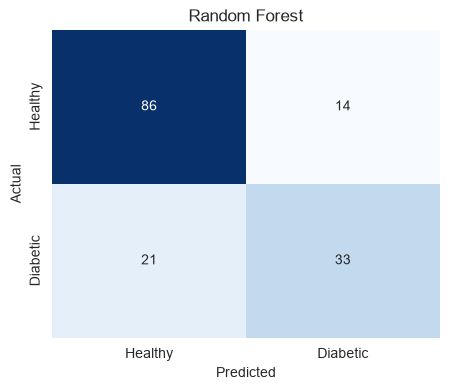

In [39]:
show_confusion_matrix('Random Forest')

#### Random Forest
Of the 54 diabetic patients, the model correctly found **33** and missed **21**. Of the 100 healthy patients, it correctly identified **86** and wrongly flagged **14**. It makes few false alarms, but it still misses about 4 in 10 diabetic patients (recall = 33/54 = 0.61).

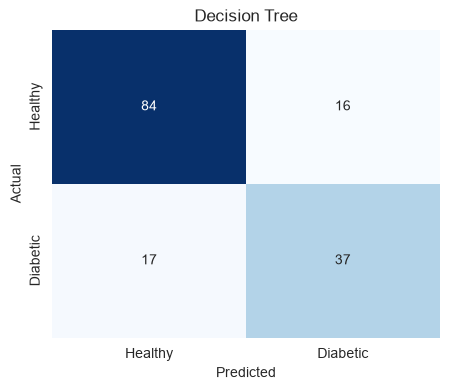

In [40]:
show_confusion_matrix('Decision Tree')

#### Decision Tree
The model correctly found **37** of the 54 diabetic patients and missed **17**. It correctly identified **84** healthy patients and wrongly flagged **16**. It has recall = 37/54 = 0.69.

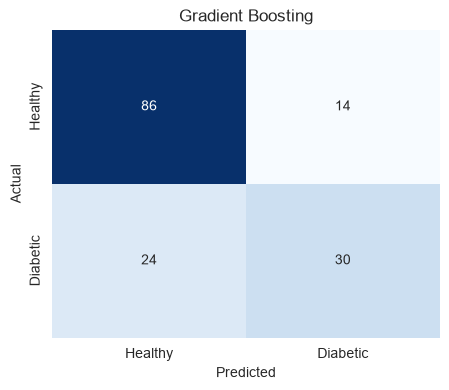

In [41]:
show_confusion_matrix('Gradient Boosting')

#### Gradient Boosting
The model correctly found **30** of the 54 diabetic patients and missed **24**. It correctly identified **86** healthy patients and wrongly flagged **14**. It makes few false alarms, like Random Forest, but misses a few more diabetic patients on this test set (recall = 30/54 = 0.56).

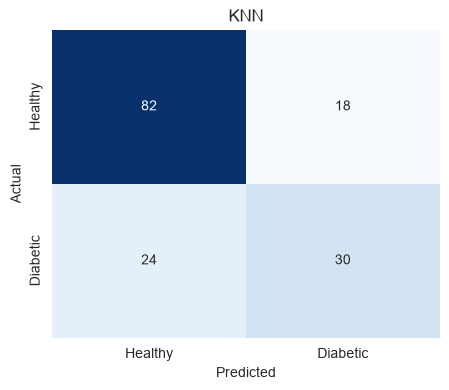

In [42]:
show_confusion_matrix('KNN')

#### KNN
The model correctly found **30** of the 54 diabetic patients and missed **24**. It correctly identified **82** healthy patients and wrongly flagged **18**. It has both more false alarms and more misses than the tree-based models, which gives it one of the lower scores (Recall = 30/54 = 0.56).

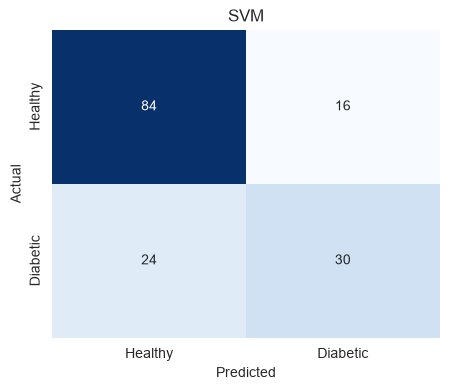

In [43]:
show_confusion_matrix('SVM')

#### SVM
The model correctly found **30** of the 54 diabetic patients and missed **24**. It correctly identified **84** healthy patients and wrongly flagged **16**. When it says "diabetic" it is usually right, but it misses more than 4 in 10 diabetic patients (recall = 30/54 = 0.56).

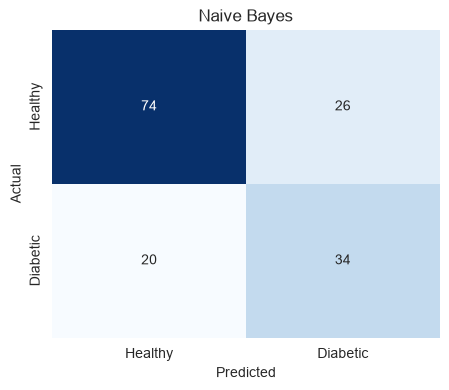

In [44]:
show_confusion_matrix('Naive Bayes')

#### Naive Bayes
The model correctly found **34** of the 54 diabetic patients and missed **20**. However, it correctly identified only **74** healthy patients and wrongly flagged **26**, the most false alarms of all six models. It catches more diabetic patients than most models, but at the cost of many healthy patients being flagged. Recall = 34/54 = 0.63

### Summary of the confusion matrices

- Every model **misses between 17 and 24 diabetic patients** out of 54, so none of them is reliable enough on its own for medical screening.
- **Decision Tree** misses the fewest (17), and **KNN and SVM** miss the most (24).
- **Naive Bayes** raises the most false alarms (26), while **Random Forest and Gradient Boosting** raise the fewest (14).
- There is a trade-off: catching more diabetic patients usually means more false alarms. In medicine, a false alarm leads to a follow-up test, while a miss can leave diabetes untreated, so reducing misses is usually the priority.

## ROC and Precision-Recall curves

Every model gives a **probability** of diabetes. By default, a probability above 0.5 is called "diabetic", but we can move that threshold. The curves show how the model performs at **all** thresholds.

- **ROC curve:** true positive rate (recall) against false positive rate. The higher and further to the top-left, the better. The dashed diagonal line is random guessing. The area under the curve is the **AUC**.
- **Precision-Recall curve:** precision against recall. It is especially useful when the classes are imbalanced, as here (35% diabetic).

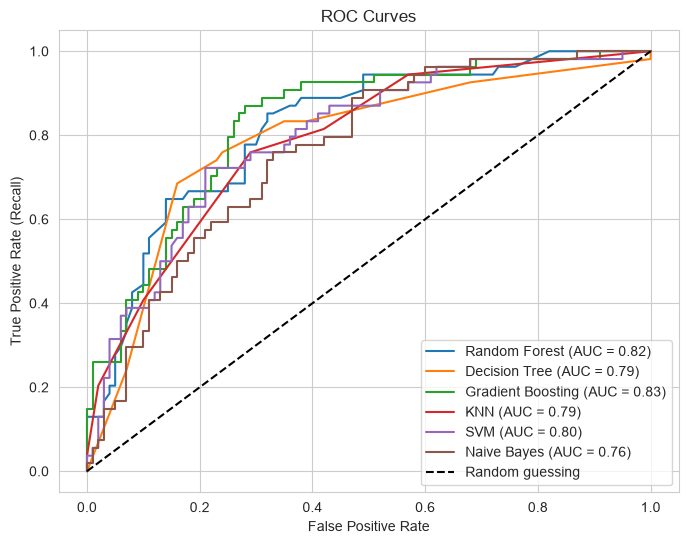

In [45]:
plt.figure(figsize=(8, 6))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves')
plt.legend()
plt.show()

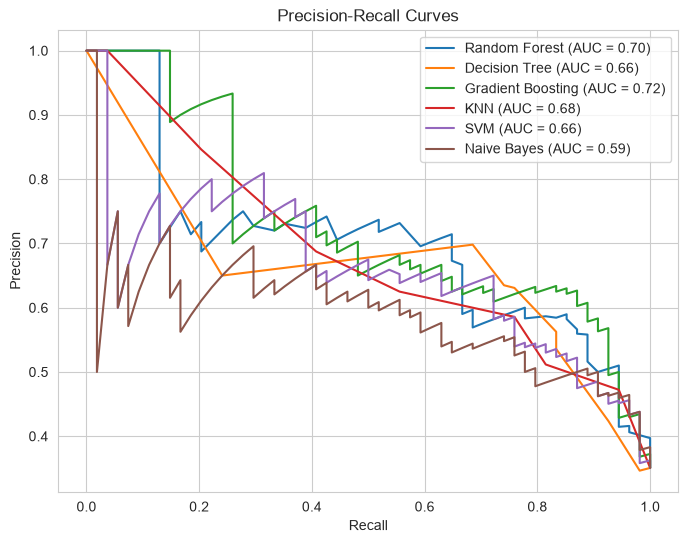

In [46]:
plt.figure(figsize=(8, 6))
for name, prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    plt.plot(recall, precision, label=f'{name} (AUC = {auc(recall, precision):.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend()
plt.show()

## Which features matter most?

A Random Forest can tell us how much each feature helped its decisions (**feature importance**). Longer bar = more important. This answers the practical question: *what drives diabetes risk in this data?*

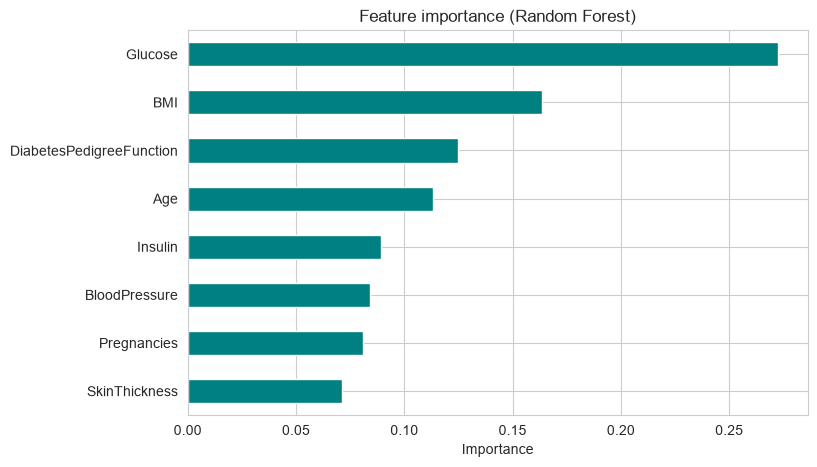

In [47]:
rf = models['Random Forest'].named_steps['model']   # take the Random Forest out of its pipeline
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

importance.plot(kind='barh', figsize=(8, 5), color='teal')
plt.title('Feature importance (Random Forest)')
plt.xlabel('Importance')
plt.show()

**Reading:** in our run, **Glucose** was clearly the most important feature (about 27%), followed by **BMI**, **DiabetesPedigreeFunction** and **Age**. This agrees with the EDA, where high glucose, high BMI and older age were more common among diabetic patients.

## Comparing the models

We compare the cross-validated scores side by side.

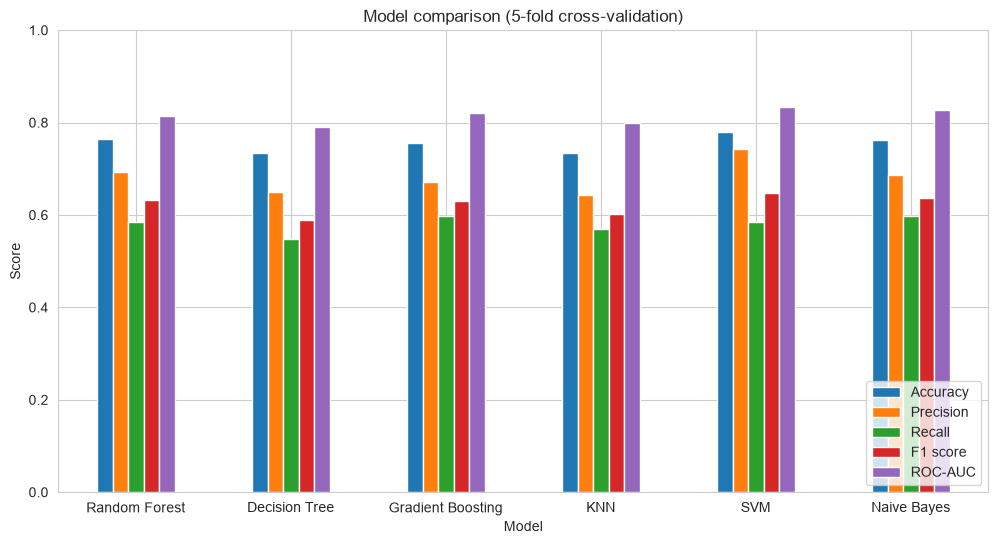

In [48]:
cv_df.plot(kind='bar', figsize=(12, 6))
plt.ylim(0, 1)
plt.ylabel('Score')
plt.title('Model comparison (5-fold cross-validation)')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [49]:
for metric in cv_df.columns:
    best = cv_df[metric].idxmax()
    print(f'Best {metric:10s}: {best} ({cv_df.loc[best, metric]})')

Best Accuracy  : SVM (0.78)
Best Precision : SVM (0.742)
Best Recall    : Gradient Boosting (0.598)
Best F1 score  : SVM (0.648)
Best ROC-AUC   : SVM (0.833)


### Conclusion

Six machine learning classification algorithms were evaluated using stratified five-fold cross-validation on the training dataset.

The Support Vector Machine (SVM) demonstrated the strongest overall performance, achieving the highest mean accuracy (78.0%), precision (74.2%), F1-score (64.8%) and ROC-AUC (83.3%) among the evaluated classifiers.

Gradient Boosting and Naive Bayes achieved the highest mean recall of 59.8%, slightly outperforming SVM in identifying positive diabetic cases at the default classification threshold.

The findings suggest that SVM provides the best overall balance of predictive performance among the evaluated models, while the differences in recall highlight the importance of considering the intended application when selecting a classifier.

However, the relatively modest recall values indicate that a considerable proportion of diabetic observations remain undetected. Therefore, further investigation into classification threshold optimization and model improvement is warranted.

## Risk prediction

Instead of only saying "diabetic" or "healthy", we use the model's **probability** and group patients into risk levels:

| Probability of diabetes | Risk level |
|---|---|
| 0.00 to 0.33 | Low |
| 0.34 to 0.66 | Medium |
| 0.67 to 1.00 | High |

We use the model with the best cross-validated ROC-AUC, because ROC-AUC measures how well the model ranks patients from low to high risk.

In [50]:
best_name = cv_df['ROC-AUC'].idxmax()
best_model = models[best_name]
print('Model used for risk prediction:', best_name)

risk_prob = best_model.predict_proba(X_test)[:, 1]

risk_df = X_test.copy()
risk_df['Actual outcome'] = y_test.values
risk_df['Diabetes probability'] = risk_prob.round(2)
risk_df['Risk level'] = pd.cut(risk_prob, bins=[0, 0.33, 0.66, 1.0],
                               labels=['Low', 'Medium', 'High'], include_lowest=True)

risk_df[['Glucose', 'BMI', 'Age', 'Actual outcome', 'Diabetes probability', 'Risk level']].head(10)

Model used for risk prediction: SVM


,Glucose,BMI,Age,Actual outcome,Diabetes probability,Risk level
44,159.0,27.4,40,0,0.69,High
672,68.0,35.5,47,0,0.16,Low
700,122.0,35.9,26,0,0.20,Low
630,114.0,27.4,34,1,0.38,Medium
81,74.0,NaN,22,0,0.13,Low
389,100.0,31.6,28,0,0.27,Low
387,105.0,43.3,45,1,0.40,Medium
408,197.0,25.9,39,1,0.81,High
163,100.0,29.7,21,0,0.08,Low
335,165.0,47.9,26,0,0.84,High


In [51]:
# How many patients in each risk level really have diabetes?
pd.crosstab(risk_df['Risk level'], risk_df['Actual outcome'],
            rownames=['Risk level'], colnames=['Actual (0 = healthy, 1 = diabetic)'])

"Actual (0 = healthy, 1 = diabetic)",0,1
Risk level,,
Low,75,15
Medium,16,18
High,9,21


**Reading:** a good risk model puts few diabetic patients in the **Low** group and most diabetic patients in the **High** group. The **Medium** group is where the model is unsure, and those patients would need further testing.

### Predicting for a new patient

The pipeline accepts a patient with a missing value (here Insulin was not measured). It fills the gap with the training median automatically.

In [52]:
new_patient = pd.DataFrame({
    'Pregnancies': [2],
    'Glucose': [150],
    'BloodPressure': [80],
    'SkinThickness': [30],
    'Insulin': [np.nan],          # not measured
    'BMI': [33.0],
    'DiabetesPedigreeFunction': [0.5],
    'Age': [45]
})

probability = best_model.predict_proba(new_patient)[0, 1]
print(f'Probability of diabetes: {probability:.0%}')

Probability of diabetes: 77%


## Limitations

- The dataset is small (768 patients) and contains only women of Pima Indian heritage aged 21 or above, so the results may not apply to other groups.
- Insulin (49%) and SkinThickness (30%) are missing for many patients, so their filled-in values are estimates.
- Even the best models miss a noticeable share of diabetic patients (recall is well below 1).